# BLM3510 - Yapay Zeka Projesi

In [ ]:
!pip install optuna

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import optuna

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.5/242.5 kB 24.6 MB/s eta 0:00:00


In [ ]:
# Model Fonksiyonları

EPOCH = 50
N_TRIALS = 30

# Dataset için en iyi parametreleri bulur.
def get_best_params(X_train, X_test, y_train, y_test, n_trials=30):

    # CNN modelini rastgele hiperparametrelerle oluşturur.
    def create_cnn_model(trial):
        model = Sequential()
        model.add(Input(shape=(25, 25, 1)))
        model.add(Conv2D(trial.suggest_categorical("filters1", [16, 32]),
                         trial.suggest_categorical("kernel1", [3, 5]), activation="relu"))
        model.add(MaxPooling2D(pool_size=2))
        model.add(Conv2D(trial.suggest_categorical("filters2", [64, 96, 128]),
                         trial.suggest_categorical("kernel2", [3, 5]), activation="relu"))
        model.add(MaxPooling2D(pool_size=2))
        model.add(Flatten())
        model.add(Dense(trial.suggest_int("dense_units", 64, 180), activation="relu"))
        model.add(Dropout(trial.suggest_float("dropout", 0.2, 0.5)))
        model.add(Dense(1))
        model.compile(
            optimizer=Adam(learning_rate=trial.suggest_float("lr", 1e-4, 1e-2, log=True)),
            loss="mse"
        )
        return model

    # Modeli datayla eğitir ve mutlak hatayı döndürür.
    def objective(trial):
        model = create_cnn_model(trial)
        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        model.fit(X_train, y_train,
                  validation_split=0.2,
                  epochs=EPOCH,
                  batch_size=trial.suggest_categorical("batch_size", [16, 32, 64]),
                  callbacks=[early_stop],
                  verbose=0)
        preds = model.predict(X_test).flatten()
        mae = mean_absolute_error(y_test, preds)
        return mae

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=n_trials)

    best_params = study.best_trial.params
    return best_params

# En iyi parametrelerle modeli oluşturur ve eğitir.
def get_best_model(X_train, y_train, best_params):
  # En iyi model ile yeniden eğit
    model = Sequential()
    model.add(Input(shape=(25, 25, 1)))
    model.add(Conv2D(best_params['filters1'], best_params['kernel1'], activation='relu'))
    model.add(MaxPooling2D(pool_size=2))
    model.add(Conv2D(best_params['filters2'], best_params['kernel2'], activation='relu'))
    model.add(MaxPooling2D(pool_size=2))
    model.add(Flatten())
    model.add(Dense(best_params['dense_units'], activation='relu'))
    model.add(Dropout(best_params['dropout']))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=best_params['lr']), loss='mse')

    model.fit(X_train, y_train,
              epochs=EPOCH,
              batch_size=best_params['batch_size'],
              validation_split=0.2,
              callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
              verbose=0)

    return model

In [ ]:
# Grafik Fonksiyonları

# Y etiket dağılımını çizer.
def plot_label_distribution(y, title):
    plt.figure(figsize=(8, 5))
    plt.hist(y, bins=np.arange(min(y), max(y) + 2), edgecolor='black')
    plt.title(f"{title} - Y Etiketlerinin Dağılımı")
    plt.xlabel("Etiket Değeri")
    plt.ylabel("Frekans")
    plt.grid(True)
    plt.show()

def plot_test_vs_pred(y_test, y_pred, title):
    plt.figure(figsize=(6,6))
    plt.scatter(y_test, y_pred, alpha=0.5, edgecolors='k')
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.xlabel("Gerçek Değer (y_test)")
    plt.ylabel("Tahmin (y_pred)")
    plt.title(f"{title} - Gerçek vs Tahmin")
    plt.grid(True)
    plt.axis("equal")
    plt.show()

def plot_pred_distribution(y_test, y_pred, title):
    errors = y_pred - y_test

    plt.figure(figsize=(7,4))
    plt.hist(errors, bins=30, edgecolor='k')
    plt.title(f"{title} - Tahmin Hatalarının Dağılımı")
    plt.xlabel("Tahmin Hatası (y_pred - y_test)")
    plt.ylabel("Frekans")
    plt.grid(True)
    plt.show()

def plot_pred_series(y_test, y_pred, title):
    plt.figure(figsize=(10,4))
    plt.plot(y_test, label="Gerçek", marker='o')
    plt.plot(y_pred, label="Tahmin", marker='x')
    plt.title(f"{title} - Gerçek ve Tahmin Değerleri")
    plt.xlabel("Örnek İndeksi")
    plt.ylabel("Mesafe")
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_results(results_df, metric):
    plt.figure(figsize=(10, 6))
    sns.barplot(data=results_df, x="dataset", y=metric, hue="train_size")
    plt.title(f"Eğitim Seti Boyutuna Göre {metric.capitalize()} Skoru")
    plt.xlabel("Dataset")
    plt.ylabel(f"{metric.capitalize()} Skoru")
    plt.grid(True)
    plt.show()

In [ ]:
# Sonuçlar en son görselleştirilmek üzere saklanır.
results = []

## A KISMI

In [ ]:
df = pd.read_csv("dataset_A.csv")

In [ ]:
X = df.drop(columns=["id", "distance"]).values
y = df["distance"].values

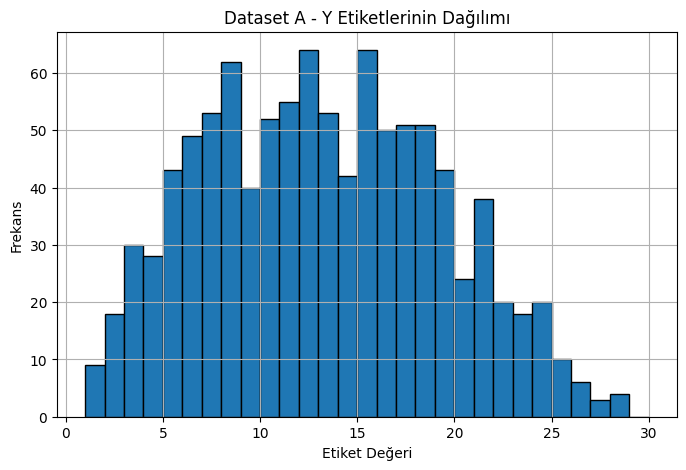

In [ ]:
plot_label_distribution(y, "Dataset A")

In [ ]:
X = X.reshape(-1, 25, 25, 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_half, _, y_train_half, _ = train_test_split(X_train, y_train, train_size=0.5, random_state=42)

X_train_quarter, _, y_train_quarter, _ = train_test_split(X_train, y_train, train_size=0.25, random_state=42)

### Eğitim Kümesinin %100'ü

In [ ]:
best_params = get_best_params(X_train, X_test, y_train, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train, y_train, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "A",
    "train_size": 1.00,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 15:54:02,967] A new study created in memory with name: no-name-1831a046-1faa-437e-b181-e5b63fc1cd99


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step


[I 2025-05-22 15:54:16,091] Trial 0 finished with value: 3.2052907046931853 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 98, 'dropout': 0.3611549084282314, 'lr': 0.003596470376358133, 'batch_size': 16}. Best is trial 0 with value: 3.2052907046931853.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step


[I 2025-05-22 15:54:28,187] Trial 1 finished with value: 4.3661957809140945 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 74, 'dropout': 0.3219165970017103, 'lr': 0.0006055471942811254, 'batch_size': 16}. Best is trial 0 with value: 3.2052907046931853.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 15:58:25,797] Trial 28 finished with value: 4.746343722511389 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 5, 'dense_units': 65, 'dropout': 0.22386857277882607, 'lr': 0.000737002309465825, 'batch_size': 64}. Best is trial 20 with value: 2.7883099100266886.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step


[I 2025-05-22 15:58:35,373] Trial 29 finished with value: 4.653748689209964 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 87, 'dropout': 0.26835434023853477, 'lr': 0.00030291787241980923, 'batch_size': 32}. Best is trial 20 with value: 2.7883099100266886.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 108, 'dropout': 0.278518496554908, 'lr': 0.0011372408909198883, 'batch_size': 16}

MSE: 14.7064
MAE: 2.8283
R2: 0.5938


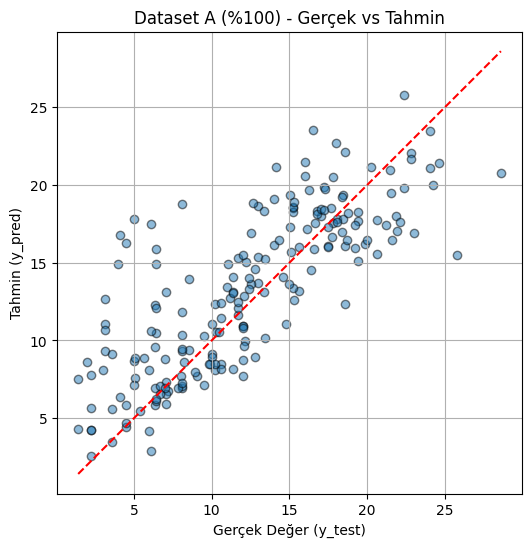

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset A (%100)")

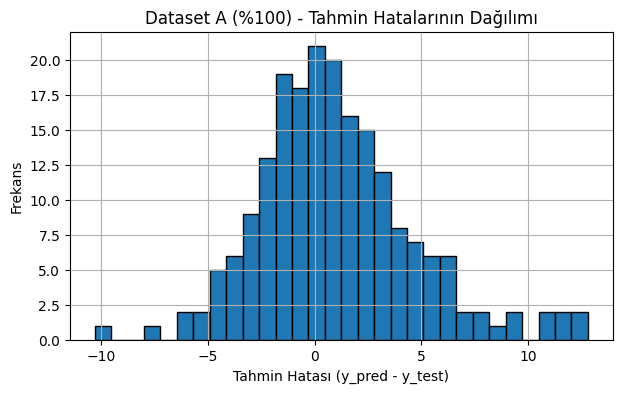

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset A (%100)")

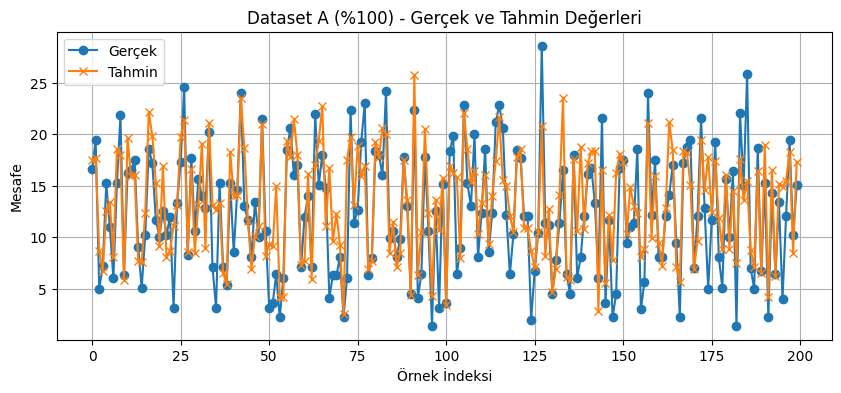

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset A (%100)")

### Eğitim Kümesinin %50'si

In [ ]:
best_params = get_best_params(X_train_half, X_test, y_train_half, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_half, y_train_half, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "A",
    "train_size": 0.50,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 15:58:47,168] A new study created in memory with name: no-name-0676f3cc-9297-4441-82e7-25e7362a9fb9


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


[I 2025-05-22 15:58:55,824] Trial 0 finished with value: 4.960354951239709 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 147, 'dropout': 0.2587489592813508, 'lr': 0.0003912584383448909, 'batch_size': 32}. Best is trial 0 with value: 4.960354951239709.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


[I 2025-05-22 15:59:03,953] Trial 1 finished with value: 4.948556166141944 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 68, 'dropout': 0.2818098267929821, 'lr': 0.0009160534507924928, 'batch_size': 64}. Best is trial 1 with value: 4.948556166141944.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:01:46,515] Trial 28 finished with value: 4.776840707325076 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 136, 'dropout': 0.3155666514666047, 'lr': 0.001320118313534462, 'batch_size': 64}. Best is trial 11 with value: 4.459133226564899.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


[I 2025-05-22 16:01:51,512] Trial 29 finished with value: 4.831344145130871 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 145, 'dropout': 0.43830528760406334, 'lr': 0.004271542626296915, 'batch_size': 16}. Best is trial 11 with value: 4.459133226564899.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 179, 'dropout': 0.48465257326889094, 'lr': 0.008611183525904677, 'batch_size': 32}

MSE: 32.2109
MAE: 4.3714
R2: 0.1103


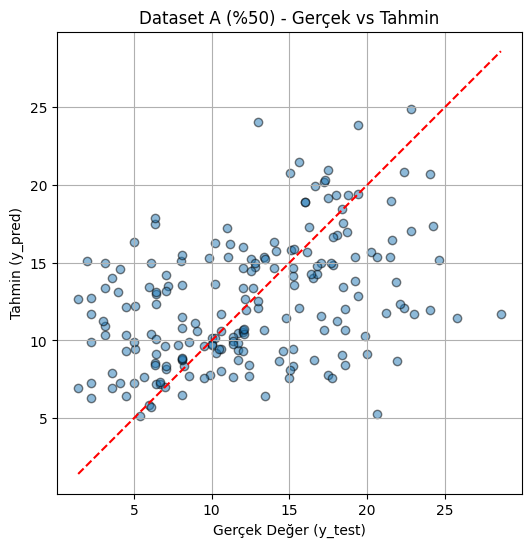

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset A (%50)")

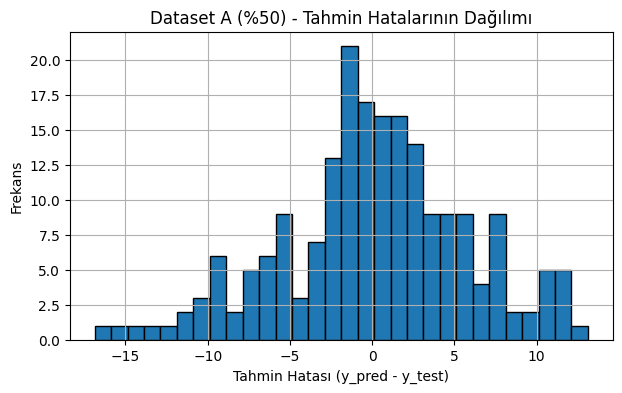

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset A (%50)")

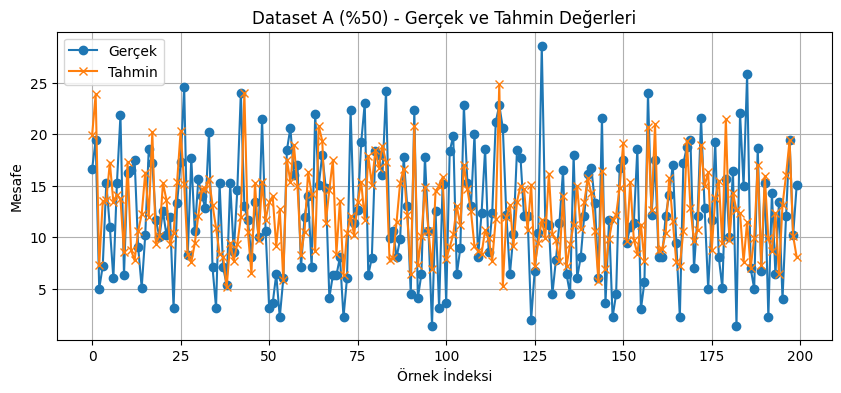

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset A (%50)")

### Eğitim Kümesinin %25'i

In [ ]:
best_params = get_best_params(X_train_quarter, X_test, y_train_quarter, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_quarter, y_train_quarter, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "A",
    "train_size": 0.25,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:01:57,137] A new study created in memory with name: no-name-190200ad-16f2-4b18-ad76-266b9f494222


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


[I 2025-05-22 16:02:06,129] Trial 0 finished with value: 5.018335444746 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 96, 'kernel2': 5, 'dense_units': 110, 'dropout': 0.34269211486597606, 'lr': 0.0019328527592366708, 'batch_size': 64}. Best is trial 0 with value: 5.018335444746.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:02:10,892] Trial 1 finished with value: 5.033209039183642 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 96, 'kernel2': 5, 'dense_units': 92, 'dropout': 0.3183275136420078, 'lr': 0.0023732194163627353, 'batch_size': 16}. Best is trial 0 with value: 5.018335444746.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


[I 2025-05-22 16:05:03,881] Trial 28 finished with value: 4.77534846382173 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 129, 'dropout': 0.35007310528746016, 'lr': 0.005295460741941426, 'batch_size': 16}. Best is trial 12 with value: 4.729177506130724.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:05:10,643] Trial 29 finished with value: 4.844916063916369 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 130, 'dropout': 0.3544862360171114, 'lr': 0.002075856705443604, 'batch_size': 16}. Best is trial 12 with value: 4.729177506130724.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 139, 'dropout': 0.3845597654151973, 'lr': 0.004914833333563555, 'batch_size': 32}

MSE: 34.3671
MAE: 4.8038
R2: 0.0507


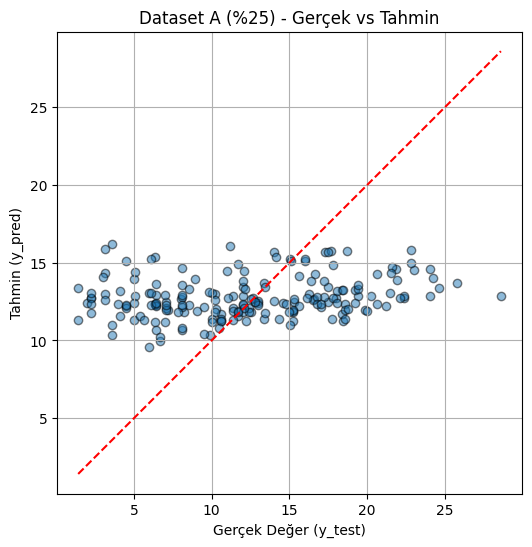

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset A (%25)")

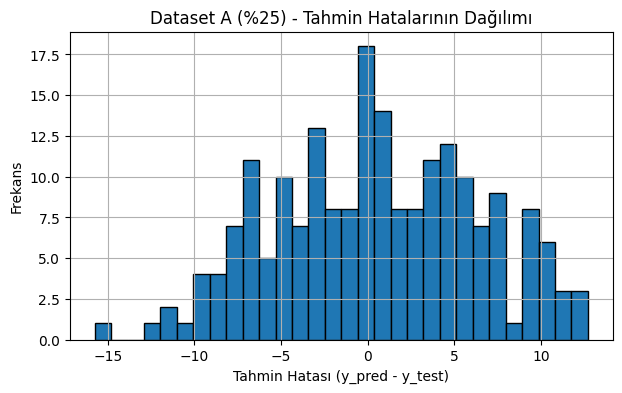

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset A (%25)")

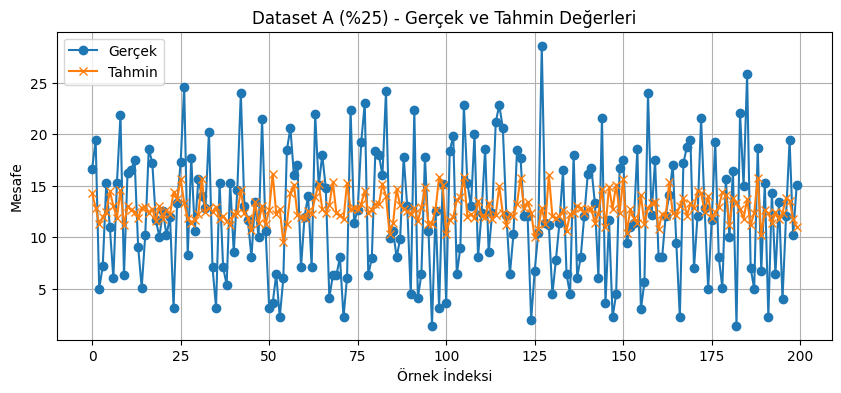

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset A (%25)")

## B KISMI

In [ ]:
df = pd.read_csv("dataset_BC.csv")

In [ ]:
X = df.drop(columns=["id", "distance_min", "distance_max"]).values
y = df["distance_min"].values

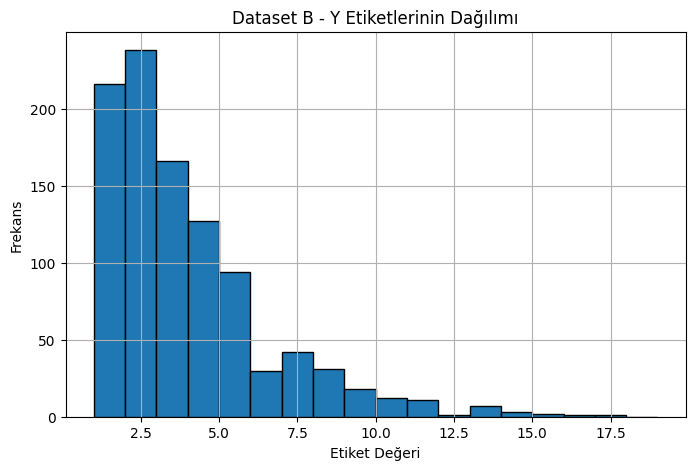

In [ ]:
plot_label_distribution(y, "Dataset B")

In [ ]:
X = X.reshape(-1, 25, 25, 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_half, _, y_train_half, _ = train_test_split(X_train, y_train, train_size=0.5, random_state=42)

X_train_quarter, _, y_train_quarter, _ = train_test_split(X_train, y_train, train_size=0.25, random_state=42)

### Eğitim Kümesinin %100'ü

In [ ]:
best_params = get_best_params(X_train, X_test, y_train, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train, y_train, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "B",
    "train_size": 1.00,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:05:16,034] A new study created in memory with name: no-name-c4e3dbbc-df8a-43e5-81fe-be5cebfbddf4


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:05:24,159] Trial 0 finished with value: 1.6376045010592037 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 5, 'dense_units': 104, 'dropout': 0.23332050445656113, 'lr': 0.007640305507499292, 'batch_size': 16}. Best is trial 0 with value: 1.6376045010592037.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:05:30,691] Trial 1 finished with value: 1.6938153055366103 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 64, 'kernel2': 5, 'dense_units': 150, 'dropout': 0.4614905295582046, 'lr': 0.0016237022324635485, 'batch_size': 64}. Best is trial 0 with value: 1.6376045010592037.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:09:24,318] Trial 28 finished with value: 1.4089052792255288 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 142, 'dropout': 0.4183511968378818, 'lr': 0.0005168851618797988, 'batch_size': 16}. Best is trial 25 with value: 1.3543329426027657.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:09:36,164] Trial 29 finished with value: 1.3753305911985316 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 5, 'dense_units': 165, 'dropout': 0.3469513275469086, 'lr': 0.00014749769674156214, 'batch_size': 16}. Best is trial 25 with value: 1.3543329426027657.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 148, 'dropout': 0.4080264856296999, 'lr': 0.0001606961582834583, 'batch_size': 16}

MSE: 3.7862
MAE: 1.4509
R2: 0.2724


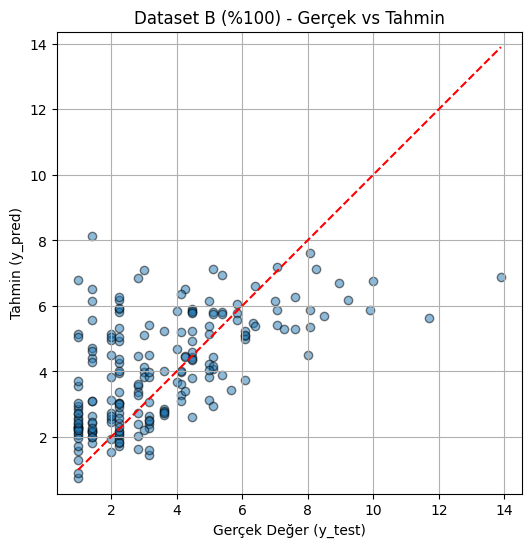

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset B (%100)")

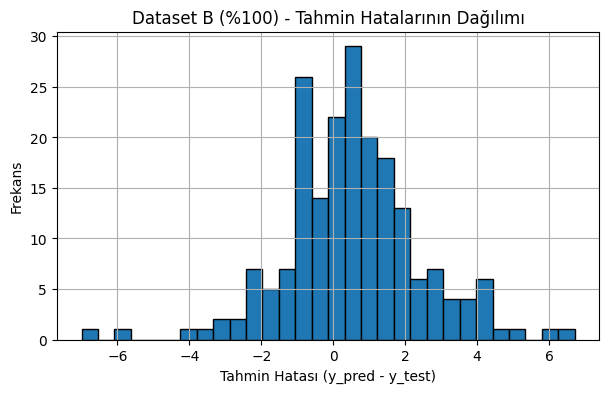

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset B (%100)")

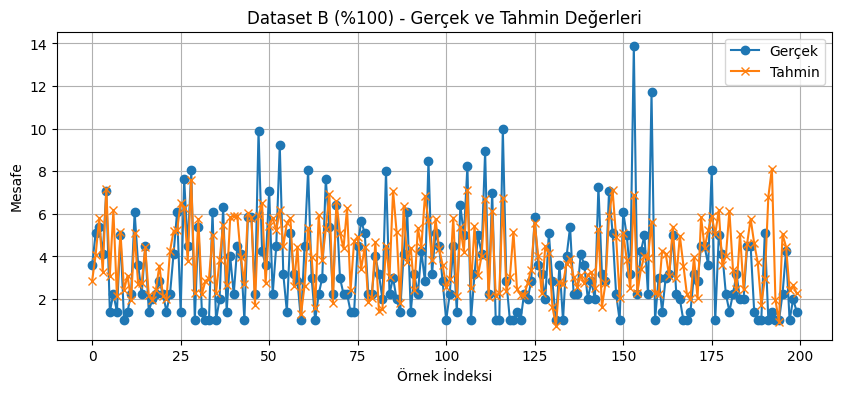

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset B (%100)")

### Eğitim Kümesinin %50'si

In [ ]:
best_params = get_best_params(X_train_half, X_test, y_train_half, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_half, y_train_half, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "B",
    "train_size": 0.50,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:09:47,898] A new study created in memory with name: no-name-4a8c55c1-8760-4e74-b58d-4958b630ceeb


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:09:55,542] Trial 0 finished with value: 1.5309790436289215 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 177, 'dropout': 0.2173818115955545, 'lr': 0.0013636301117544455, 'batch_size': 32}. Best is trial 0 with value: 1.5309790436289215.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:10:02,227] Trial 1 finished with value: 1.618659926780483 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 139, 'dropout': 0.3298162986759703, 'lr': 0.0010489698064704784, 'batch_size': 16}. Best is trial 0 with value: 1.5309790436289215.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:13:24,623] Trial 28 finished with value: 1.7204169027676923 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 119, 'dropout': 0.2763789735938003, 'lr': 0.00229402976796086, 'batch_size': 64}. Best is trial 22 with value: 1.3917497256779574.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:13:32,595] Trial 29 finished with value: 1.5041467507807953 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 179, 'dropout': 0.22776792268526969, 'lr': 0.0008102051643268783, 'batch_size': 16}. Best is trial 22 with value: 1.3917497256779574.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 147, 'dropout': 0.3009139076297191, 'lr': 0.00040226545774951647, 'batch_size': 32}

MSE: 3.5471
MAE: 1.4257
R2: 0.3183


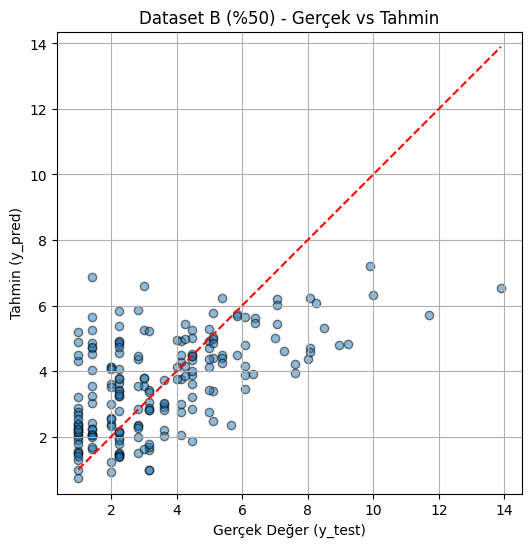

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset B (%50)")

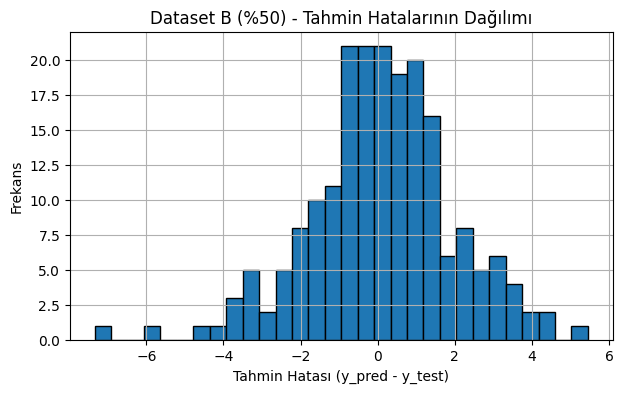

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset B (%50)")

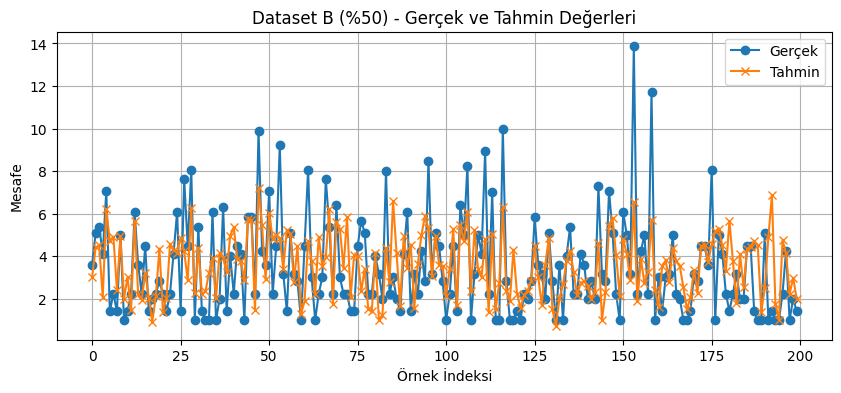

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset B (%50)")

### Eğitim Kümesinin %25'i

In [ ]:
best_params = get_best_params(X_train_quarter, X_test, y_train_quarter, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_quarter, y_train_quarter, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "B",
    "train_size": 0.25,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:13:41,348] A new study created in memory with name: no-name-fef33316-ae27-44fe-b8a7-394d24c11b91


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


[I 2025-05-22 16:13:47,529] Trial 0 finished with value: 1.7035578542780434 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 163, 'dropout': 0.32668260049701614, 'lr': 0.0037079626227683603, 'batch_size': 64}. Best is trial 0 with value: 1.7035578542780434.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:13:53,369] Trial 1 finished with value: 1.7409099243830386 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 5, 'dense_units': 156, 'dropout': 0.39207045572963484, 'lr': 0.0054334474345050085, 'batch_size': 64}. Best is trial 0 with value: 1.7035578542780434.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:16:48,884] Trial 28 finished with value: 1.726418452270297 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 92, 'dropout': 0.42875037689574585, 'lr': 0.0001894410337523318, 'batch_size': 32}. Best is trial 12 with value: 1.609531249937313.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:16:53,877] Trial 29 finished with value: 1.684868204248349 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 120, 'dropout': 0.3203552358344626, 'lr': 0.0018190775566213385, 'batch_size': 32}. Best is trial 12 with value: 1.609531249937313.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 64, 'dropout': 0.2574282600240493, 'lr': 0.00046878101175049693, 'batch_size': 16}

MSE: 4.7526
MAE: 1.7126
R2: 0.0866


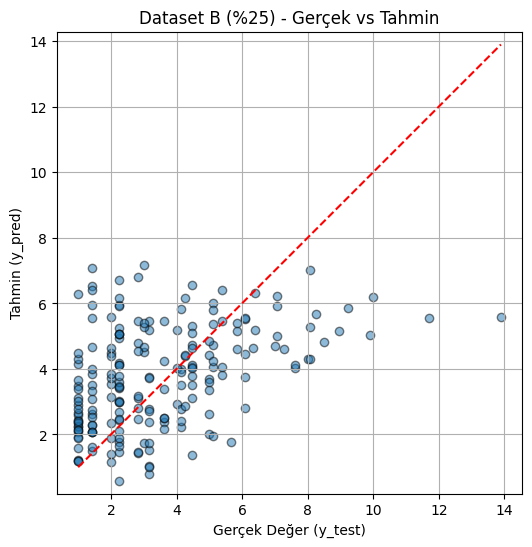

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset B (%25)")

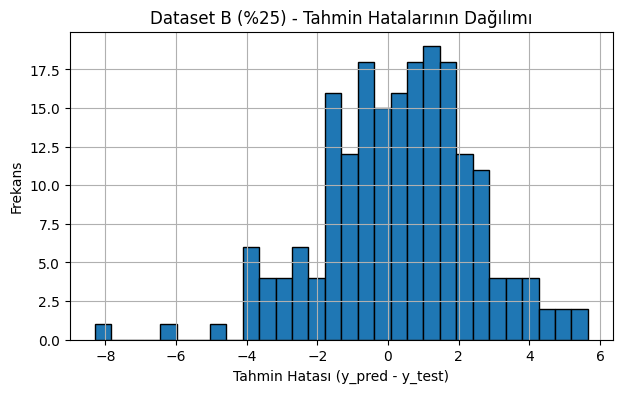

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset B (%25)")

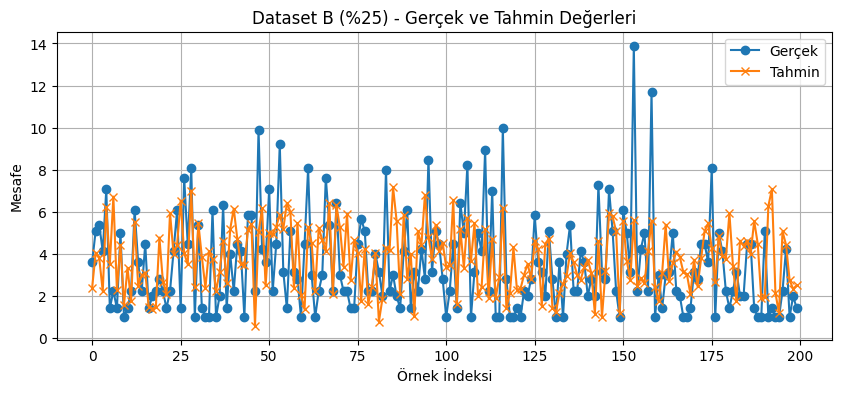

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset B (%25)")

## C KISMI

In [ ]:
df = pd.read_csv("dataset_BC.csv")

In [ ]:
X = df.drop(columns=["id", "distance_min", "distance_max"]).values
y = df["distance_max"].values

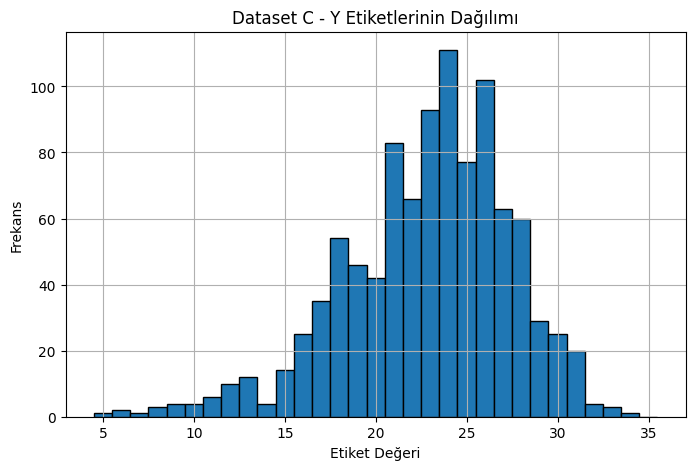

In [ ]:
plot_label_distribution(y, "Dataset C")

In [ ]:
X = X.reshape(-1, 25, 25, 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_half, _, y_train_half, _ = train_test_split(X_train, y_train, train_size=0.5, random_state=42)

X_train_quarter, _, y_train_quarter, _ = train_test_split(X_train, y_train, train_size=0.25, random_state=42)

### Eğitim Kümesinin %100'ü

In [ ]:
best_params = get_best_params(X_train, X_test, y_train, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train, y_train, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "C",
    "train_size": 1.00,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:17:00,620] A new study created in memory with name: no-name-c6d2c6b6-8ef7-4987-a237-fd4ca53ae28b


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:17:09,286] Trial 0 finished with value: 3.2027265760216452 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 179, 'dropout': 0.2316703940572447, 'lr': 0.0015676296263481917, 'batch_size': 64}. Best is trial 0 with value: 3.2027265760216452.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:17:20,573] Trial 1 finished with value: 3.270556959570688 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 129, 'dropout': 0.44300793503305524, 'lr': 0.00019658576148951046, 'batch_size': 16}. Best is trial 0 with value: 3.2027265760216452.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


[I 2025-05-22 16:20:21,181] Trial 28 finished with value: 2.9701984777084154 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 112, 'dropout': 0.28842929995770045, 'lr': 0.004392819766557953, 'batch_size': 64}. Best is trial 13 with value: 2.8639246622650534.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


[I 2025-05-22 16:20:29,538] Trial 29 finished with value: 2.865901833814598 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 178, 'dropout': 0.3381820475019343, 'lr': 0.0014819931282631722, 'batch_size': 16}. Best is trial 13 with value: 2.8639246622650534.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 151, 'dropout': 0.42094322125154304, 'lr': 0.0027909044779154167, 'batch_size': 32}

MSE: 13.6915
MAE: 2.9447
R2: 0.3048


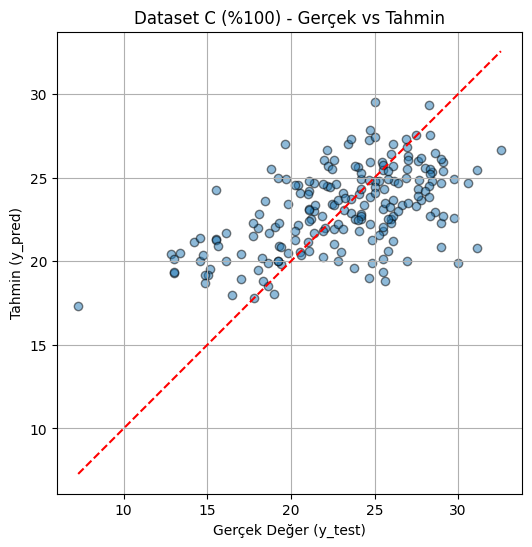

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset C (%100)")

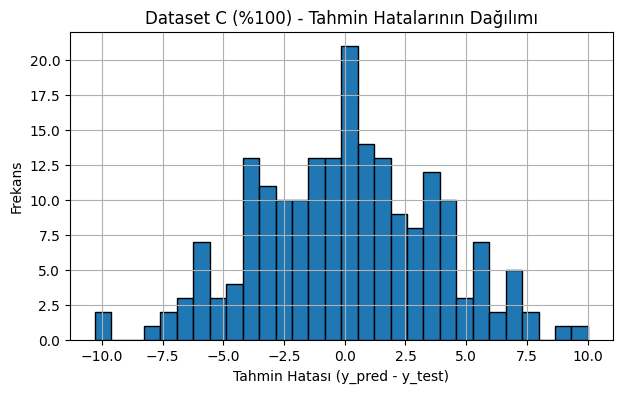

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset C (%100)")

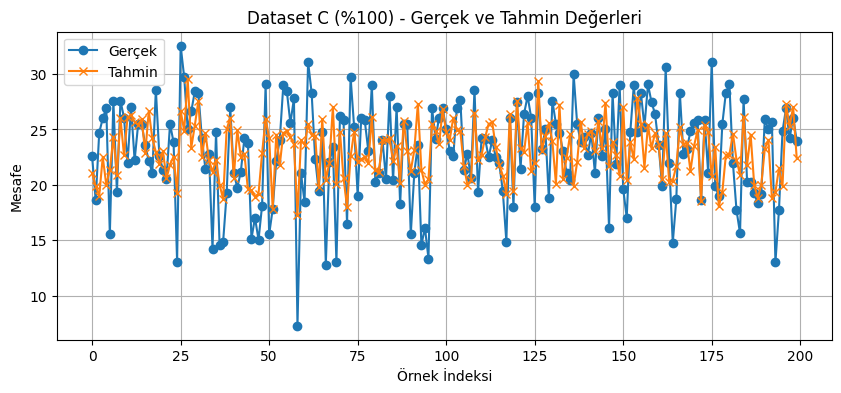

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset C (%100)")

### Eğitim Kümesinin %50'si

In [ ]:
best_params = get_best_params(X_train_half, X_test, y_train_half, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_half, y_train_half, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "C",
    "train_size": 0.50,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:20:36,061] A new study created in memory with name: no-name-767230ff-105f-4cf0-80a1-eef51ffabb09


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:20:41,069] Trial 0 finished with value: 3.438202678071464 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 124, 'dropout': 0.3283436937361025, 'lr': 0.004936225274530104, 'batch_size': 32}. Best is trial 0 with value: 3.438202678071464.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:20:48,521] Trial 1 finished with value: 3.900234316423472 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 5, 'dense_units': 107, 'dropout': 0.39599267558123885, 'lr': 0.0003108618850781773, 'batch_size': 32}. Best is trial 0 with value: 3.438202678071464.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:23:41,815] Trial 28 finished with value: 3.802906374187068 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 151, 'dropout': 0.25785215965572195, 'lr': 0.0007990951990318781, 'batch_size': 64}. Best is trial 3 with value: 3.2515092988466447.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:23:46,536] Trial 29 finished with value: 3.28593307545088 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 172, 'dropout': 0.35562065732428105, 'lr': 0.004482992819945022, 'batch_size': 16}. Best is trial 3 with value: 3.2515092988466447.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 168, 'dropout': 0.2977433439388551, 'lr': 0.0011100966978534901, 'batch_size': 32}

MSE: 17.0589
MAE: 3.4083
R2: 0.1338


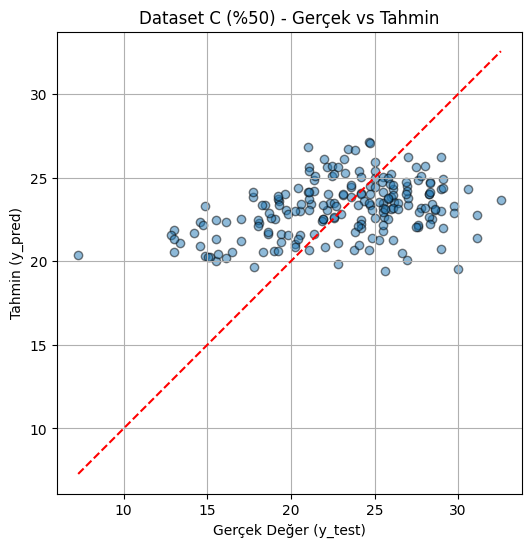

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset C (%50)")

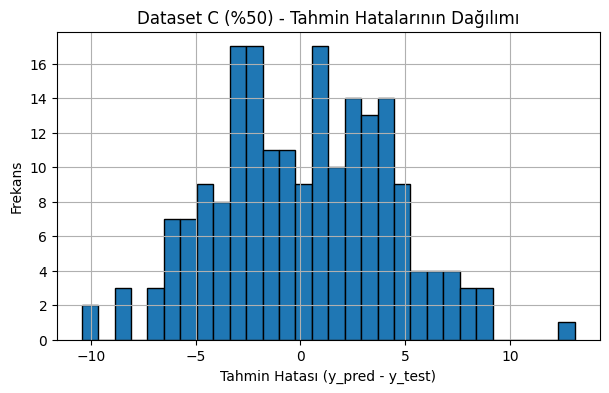

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset C (%50)")

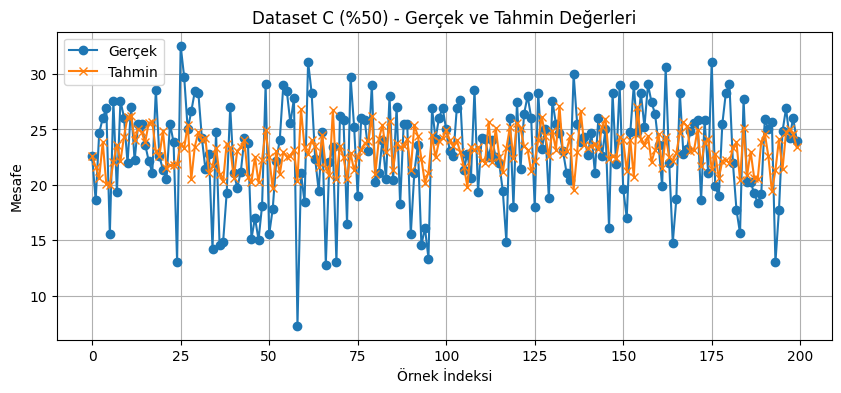

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset C (%50)")

### Eğitim Kümesinin %25'i

In [ ]:
best_params = get_best_params(X_train_quarter, X_test, y_train_quarter, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_quarter, y_train_quarter, best_params)
y_pred = model.predict(X_test).flatten()

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

results.append({
    "dataset": "C",
    "train_size": 0.25,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}")

[I 2025-05-22 16:23:53,358] A new study created in memory with name: no-name-d07641bd-7322-4801-995c-d734517584c4


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:24:00,914] Trial 0 finished with value: 3.648171658484033 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 5, 'dense_units': 95, 'dropout': 0.3519925054509595, 'lr': 0.0067910774177974064, 'batch_size': 64}. Best is trial 0 with value: 3.648171658484033.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


[I 2025-05-22 16:24:08,240] Trial 1 finished with value: 4.473168232886604 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 75, 'dropout': 0.4477221881800649, 'lr': 0.0012830359751605466, 'batch_size': 64}. Best is trial 0 with value: 3.648171658484033.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


[I 2025-05-22 16:26:45,975] Trial 28 finished with value: 3.8223051374578767 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 124, 'dropout': 0.48061535185627424, 'lr': 0.0017904681536062897, 'batch_size': 64}. Best is trial 22 with value: 3.451476164592385.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:26:51,243] Trial 29 finished with value: 3.7176258782995784 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 169, 'dropout': 0.3776231443645792, 'lr': 0.006416694793646352, 'batch_size': 32}. Best is trial 22 with value: 3.451476164592385.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 3, 'filters2': 96, 'kernel2': 3, 'dense_units': 140, 'dropout': 0.49655934672035307, 'lr': 0.005955278296361464, 'batch_size': 16}

MSE: 20.3433
MAE: 3.6314
R2: -0.0330


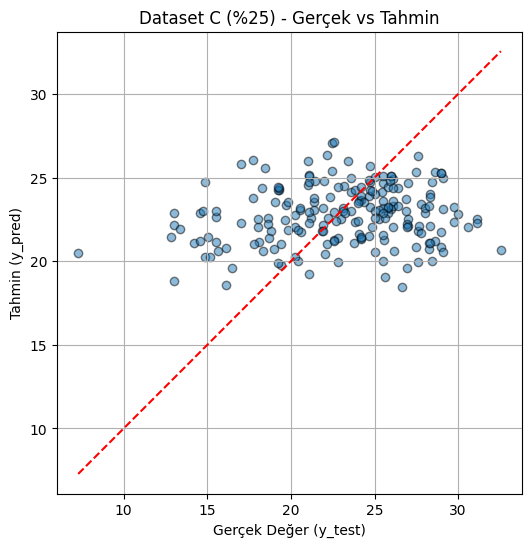

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset C (%25)")

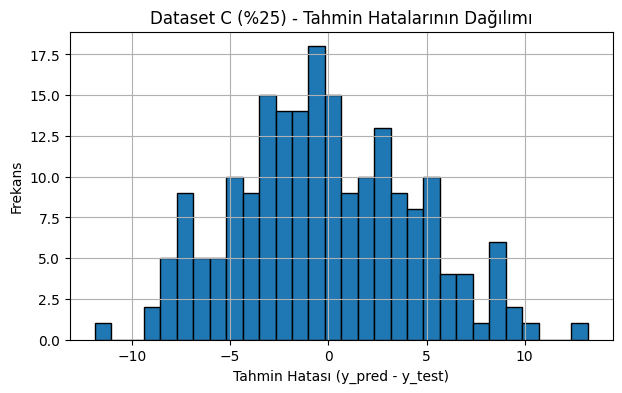

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset C (%25)")

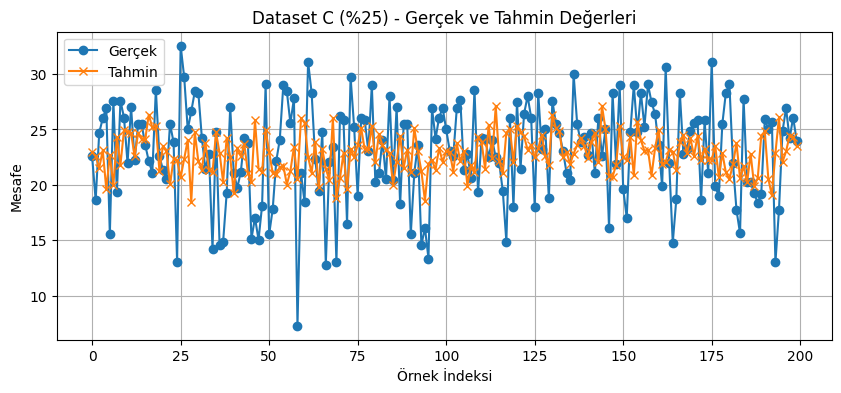

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset C (%25)")

## D KISMI

In [ ]:
df = pd.read_csv("dataset_D.csv")

In [ ]:
X = df.drop(columns=["id", "num_points"]).values
y = df["num_points"].values

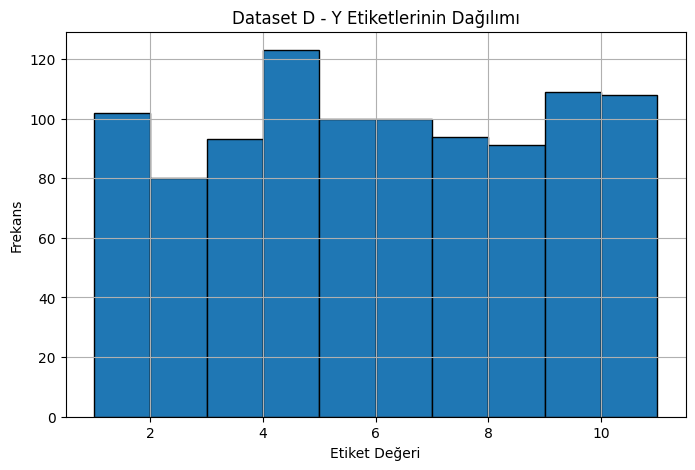

In [ ]:
plot_label_distribution(y, "Dataset D")

In [ ]:
X = X.reshape(-1, 25, 25, 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_half, _, y_train_half, _ = train_test_split(X_train, y_train, train_size=0.5, random_state=42)

X_train_quarter, _, y_train_quarter, _ = train_test_split(X_train, y_train, train_size=0.25, random_state=42)

### Eğitim Kümesinin %100'ü

In [ ]:
best_params = get_best_params(X_train, X_test, y_train, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train, y_train, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "D",
    "train_size": 1.00,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:26:59,670] A new study created in memory with name: no-name-878ac51f-898e-4c09-a0c6-5c5ed9f8eff5


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


[I 2025-05-22 16:27:08,987] Trial 0 finished with value: 0.8089441657066345 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 110, 'dropout': 0.4888512889479056, 'lr': 0.0002671291606914388, 'batch_size': 64}. Best is trial 0 with value: 0.8089441657066345.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


[I 2025-05-22 16:27:15,166] Trial 1 finished with value: 0.7434241771697998 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 108, 'dropout': 0.20247551319949564, 'lr': 0.0026464398781215594, 'batch_size': 16}. Best is trial 1 with value: 0.7434241771697998.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:31:11,466] Trial 28 finished with value: 0.7060272097587585 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 88, 'dropout': 0.4621926266127793, 'lr': 0.0014169610863908816, 'batch_size': 64}. Best is trial 6 with value: 0.6915605068206787.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:31:18,204] Trial 29 finished with value: 0.6957705616950989 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 112, 'dropout': 0.46371862424576993, 'lr': 0.005808571811091063, 'batch_size': 64}. Best is trial 6 with value: 0.6915605068206787.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 103, 'dropout': 0.41777556042631825, 'lr': 0.0005445174102416319, 'batch_size': 16}

MSE: 0.8750
MAE: 0.5850
R2: 0.8941

              precision    recall  f1-score   support

           1       0.92      0.96      0.94        23
           2       0.67      0.50      0.57        12
           3       0.53      0.62      0.57        16
           4       0.59      0.59      0.59        27
           5       0.32      0.33      0.32        18
           6       0.50      0.41      0.45        22
           7       0.31      0.59      0.41        17
           8       0.52      0.65      0.58        23
           9       0.45      0.25      0.32        20
          10       0.75      0.41      0.53        22

    accuracy                           0.54       200
   macro avg       0.56      0.53      0.53       200
weighted avg       0.56      0

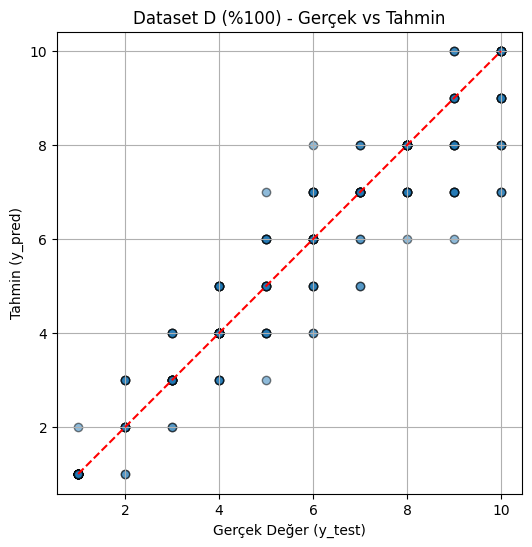

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset D (%100)")

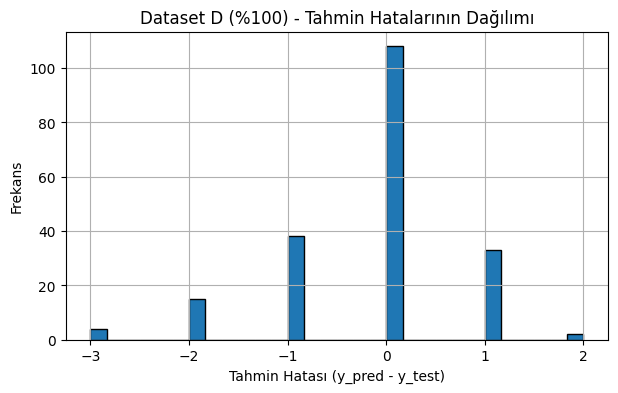

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset D (%100)")

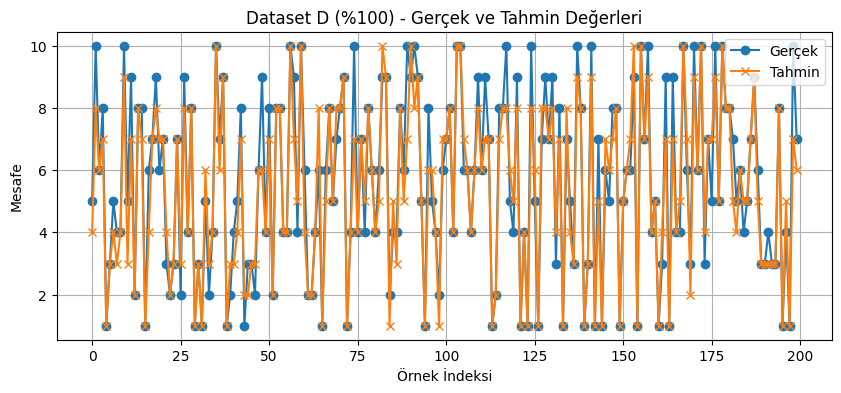

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset D (%100)")

### Eğitim Kümesinin %50'si

In [ ]:
best_params = get_best_params(X_train_half, X_test, y_train_half, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_half, y_train_half, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "D",
    "train_size": 0.50,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:31:27,847] A new study created in memory with name: no-name-19baa814-ac5b-4186-9dde-6c6c14bf3fe2


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:31:37,149] Trial 0 finished with value: 0.8198594450950623 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 70, 'dropout': 0.24347393839898082, 'lr': 0.00022194189646687203, 'batch_size': 16}. Best is trial 0 with value: 0.8198594450950623.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:31:45,202] Trial 1 finished with value: 1.2041525840759277 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 77, 'dropout': 0.20894867872045977, 'lr': 0.0003290130275013747, 'batch_size': 64}. Best is trial 0 with value: 0.8198594450950623.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:34:58,185] Trial 28 finished with value: 0.8159319162368774 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 179, 'dropout': 0.22862835834872197, 'lr': 0.0032017185508664194, 'batch_size': 32}. Best is trial 18 with value: 0.7512860298156738.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:35:06,700] Trial 29 finished with value: 0.9345700144767761 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 109, 'dropout': 0.25265728889736083, 'lr': 0.000290830676788452, 'batch_size': 32}. Best is trial 18 with value: 0.7512860298156738.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 180, 'dropout': 0.3034729032967196, 'lr': 0.005202154665096279, 'batch_size': 32}

MSE: 1.1650
MAE: 0.7550
R2: 0.8590

              precision    recall  f1-score   support

           1       0.88      0.65      0.75        23
           2       0.42      0.67      0.52        12
           3       0.43      0.38      0.40        16
           4       0.39      0.33      0.36        27
           5       0.26      0.33      0.29        18
           6       0.40      0.36      0.38        22
           7       0.15      0.29      0.20        17
           8       0.44      0.35      0.39        23
           9       0.35      0.30      0.32        20
          10       0.73      0.50      0.59        22

    accuracy                           0.41       200
   macro avg       0.45      0.42      0.42       200
weighted avg       0.46      0.41

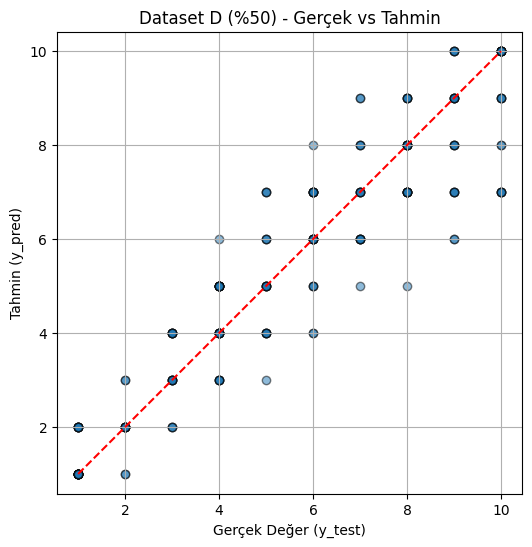

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset D (%50)")

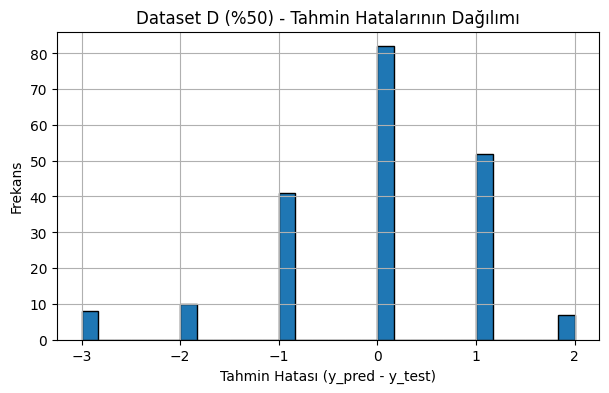

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset D (%50)")

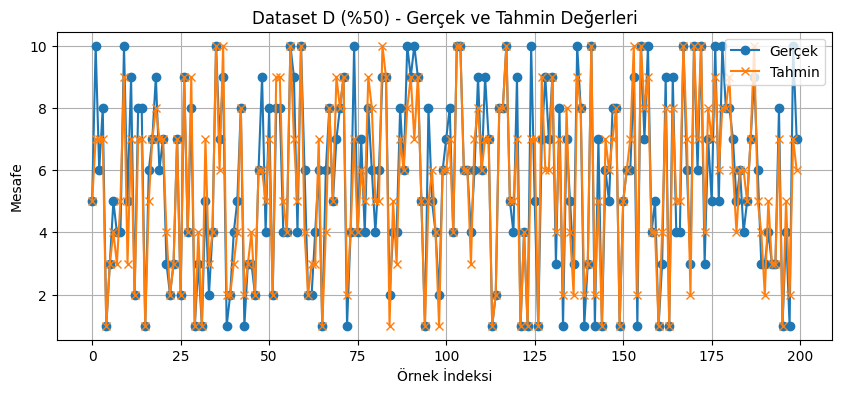

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset D (%50)")

### Eğitim Kümesinin %25'i

In [ ]:
best_params = get_best_params(X_train_quarter, X_test, y_train_quarter, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_quarter, y_train_quarter, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "D",
    "train_size": 0.25,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:35:13,299] A new study created in memory with name: no-name-7b3f240d-a410-40d1-b4a6-9a8c0805c781


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:35:20,733] Trial 0 finished with value: 1.2108407020568848 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 157, 'dropout': 0.46026740580701353, 'lr': 0.004173140938442296, 'batch_size': 64}. Best is trial 0 with value: 1.2108407020568848.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:35:28,674] Trial 1 finished with value: 1.1847041845321655 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 159, 'dropout': 0.34523960602005443, 'lr': 0.0009337263436897257, 'batch_size': 32}. Best is trial 1 with value: 1.1847041845321655.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


[I 2025-05-22 16:38:34,402] Trial 28 finished with value: 1.5461267232894897 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 172, 'dropout': 0.25846448004778566, 'lr': 0.0002666953527500399, 'batch_size': 32}. Best is trial 19 with value: 0.8760252594947815.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:38:43,029] Trial 29 finished with value: 1.2746999263763428 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 128, 'kernel2': 3, 'dense_units': 151, 'dropout': 0.3158164604363046, 'lr': 0.0005169848134367874, 'batch_size': 64}. Best is trial 19 with value: 0.8760252594947815.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 114, 'dropout': 0.20870543378110384, 'lr': 0.002546676868280974, 'batch_size': 16}

MSE: 1.4900
MAE: 0.8600
R2: 0.8196

              precision    recall  f1-score   support

           1       0.85      0.48      0.61        23
           2       0.18      0.25      0.21        12
           3       0.40      0.38      0.39        16
           4       0.52      0.44      0.48        27
           5       0.35      0.50      0.41        18
           6       0.32      0.36      0.34        22
           7       0.28      0.47      0.35        17
           8       0.29      0.35      0.31        23
           9       0.40      0.30      0.34        20
          10       0.78      0.32      0.45        22

    accuracy                           0.39       200
   macro avg       0.43      0.38      0.39       200
weighted avg       0.46      0.3

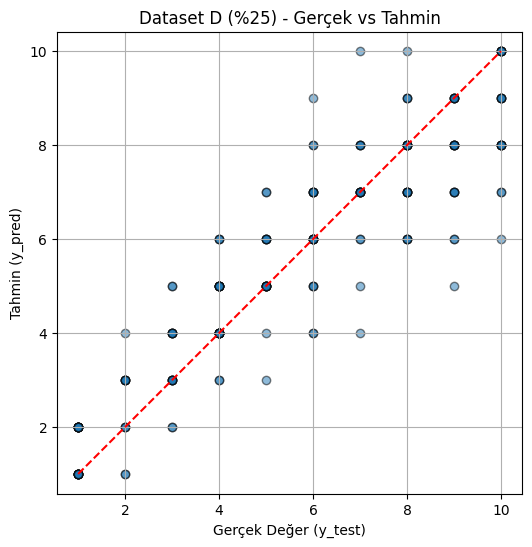

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset D (%25)")

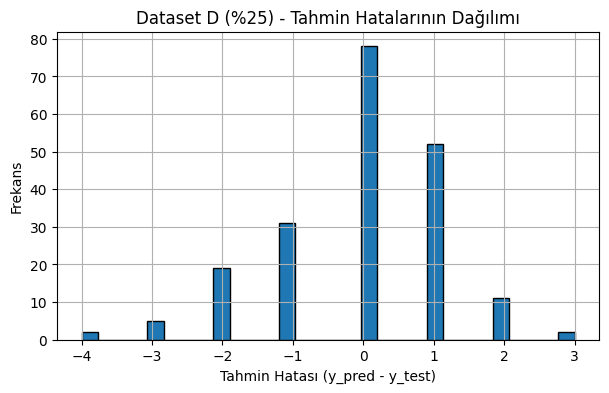

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset D (%25)")

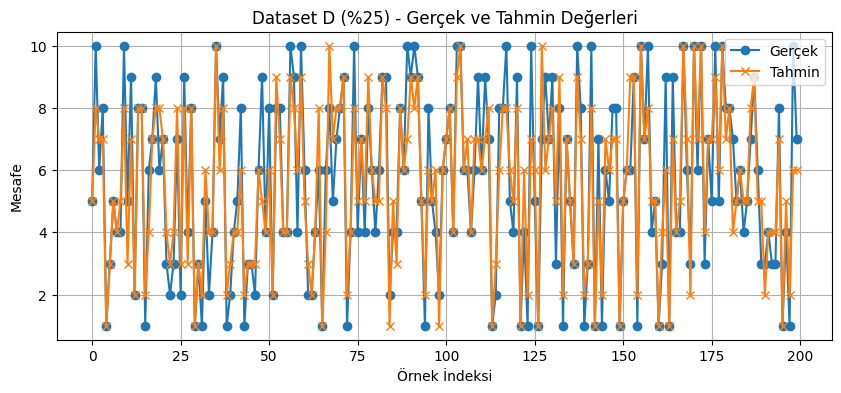

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset D (%25)")

## E KISMI

In [ ]:
df = pd.read_csv("dataset_E.csv")

In [ ]:
X = df.drop(columns=["id", "num_squares"]).values
y = df["num_squares"].values

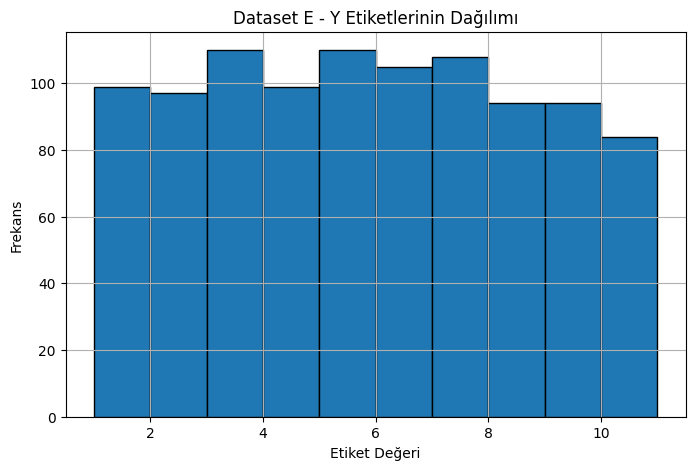

In [ ]:
plot_label_distribution(y, "Dataset E")

In [ ]:
X = X.reshape(-1, 25, 25, 1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_half, _, y_train_half, _ = train_test_split(X_train, y_train, train_size=0.5, random_state=42)

X_train_quarter, _, y_train_quarter, _ = train_test_split(X_train, y_train, train_size=0.25, random_state=42)

### Eğitim Kümesinin %100'ü

In [ ]:
best_params = get_best_params(X_train, X_test, y_train, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train, y_train, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "E",
    "train_size": 1.00,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:38:49,440] A new study created in memory with name: no-name-49b6e1be-9a25-49d1-adcf-05e237c1617e


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:38:56,765] Trial 0 finished with value: 0.7222906351089478 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 96, 'kernel2': 5, 'dense_units': 86, 'dropout': 0.3885761424301418, 'lr': 0.002226301623368274, 'batch_size': 64}. Best is trial 0 with value: 0.7222906351089478.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:39:06,849] Trial 1 finished with value: 0.7640225291252136 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 5, 'dense_units': 136, 'dropout': 0.49683878047411284, 'lr': 0.00033054205980641337, 'batch_size': 16}. Best is trial 0 with value: 0.7222906351089478.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:42:45,668] Trial 28 finished with value: 0.6584494709968567 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 128, 'kernel2': 3, 'dense_units': 110, 'dropout': 0.24436210949403564, 'lr': 0.0005740428234327662, 'batch_size': 16}. Best is trial 15 with value: 0.5634585022926331.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:42:50,946] Trial 29 finished with value: 0.7910546660423279 and parameters: {'filters1': 32, 'kernel1': 3, 'filters2': 96, 'kernel2': 5, 'dense_units': 90, 'dropout': 0.29383253787489866, 'lr': 0.002247418144758563, 'batch_size': 32}. Best is trial 15 with value: 0.5634585022926331.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 96, 'kernel2': 3, 'dense_units': 82, 'dropout': 0.27241035758508925, 'lr': 0.0029011665052775548, 'batch_size': 32}

MSE: 0.6800
MAE: 0.5500
R2: 0.9016

              precision    recall  f1-score   support

           1       0.94      1.00      0.97        16
           2       0.88      0.75      0.81        20
           3       0.53      0.45      0.49        22
           4       0.58      0.67      0.62        27
           5       0.54      0.57      0.55        23
           6       0.50      0.50      0.50        20
           7       0.22      0.22      0.22        23
           8       0.28      0.43      0.34        21
           9       0.38      0.35      0.36        17
          10       1.00      0.09      0.17        11

    accuracy                           0.52       200
   macro avg       0.58      0.50      0.50       200
weighted avg       0.55      0.5

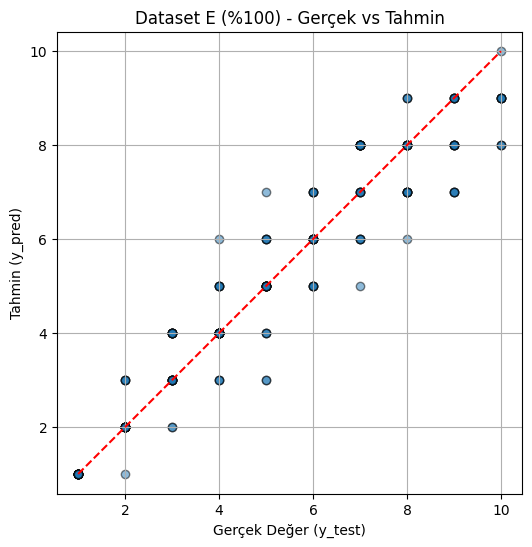

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset E (%100)")

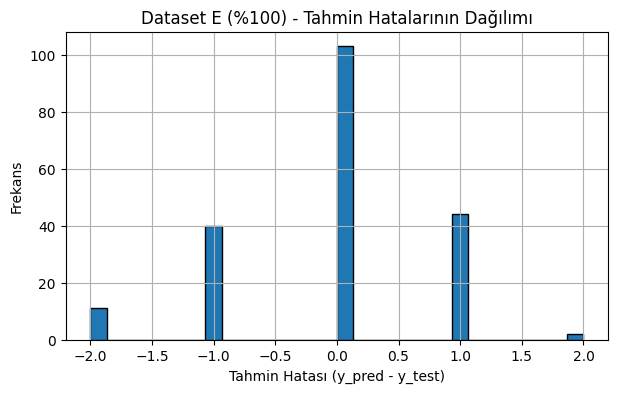

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset E (%100)")

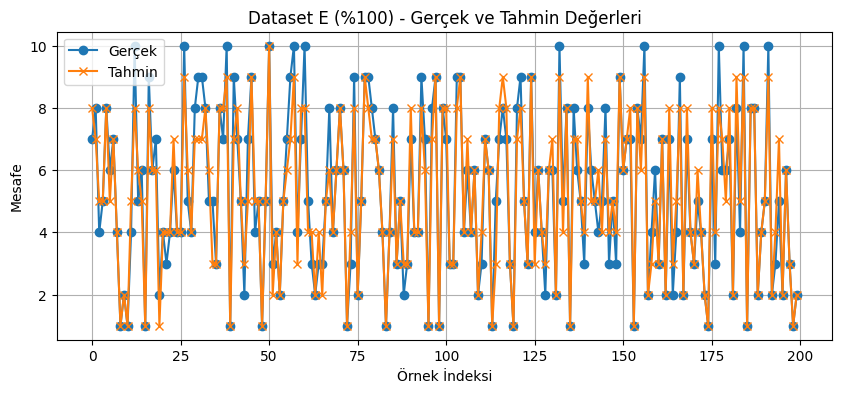

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset E (%100)")

### Eğitim Kümesinin %50'si

In [ ]:
best_params = get_best_params(X_train_half, X_test, y_train_half, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_half, y_train_half, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "E",
    "train_size": 0.50,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:42:56,941] A new study created in memory with name: no-name-64852c3a-6853-4627-8a35-192665fd110d


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:43:03,140] Trial 0 finished with value: 0.8344980478286743 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 152, 'dropout': 0.2796991224555747, 'lr': 0.0006326856859556603, 'batch_size': 32}. Best is trial 0 with value: 0.8344980478286743.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


[I 2025-05-22 16:43:08,556] Trial 1 finished with value: 0.8150950074195862 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 123, 'dropout': 0.40707655883492366, 'lr': 0.0017344637875838374, 'batch_size': 32}. Best is trial 1 with value: 0.8150950074195862.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


[I 2025-05-22 16:46:18,763] Trial 28 finished with value: 0.7694491744041443 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 156, 'dropout': 0.30506569161787445, 'lr': 0.0009873487883599518, 'batch_size': 32}. Best is trial 22 with value: 0.6872462630271912.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:46:26,534] Trial 29 finished with value: 0.6950268745422363 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 128, 'kernel2': 5, 'dense_units': 143, 'dropout': 0.3007945458606486, 'lr': 0.0007642020897047119, 'batch_size': 32}. Best is trial 22 with value: 0.6872462630271912.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 169, 'dropout': 0.23250308343377174, 'lr': 0.000495627740619673, 'batch_size': 32}

MSE: 1.0000
MAE: 0.7000
R2: 0.8554

              precision    recall  f1-score   support

           1       0.74      0.88      0.80        16
           2       0.67      0.40      0.50        20
           3       0.39      0.41      0.40        22
           4       0.48      0.44      0.46        27
           5       0.35      0.35      0.35        23
           6       0.40      0.50      0.44        20
           7       0.37      0.48      0.42        23
           8       0.35      0.52      0.42        21
           9       0.42      0.29      0.34        17
          10       0.00      0.00      0.00        11

    accuracy                           0.44       200
   macro avg       0.42      0.43      0.41       200
weighted avg       0.43      0.4

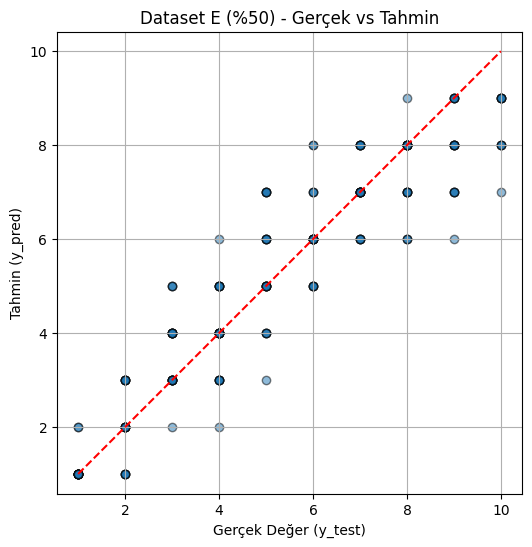

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset E (%50)")

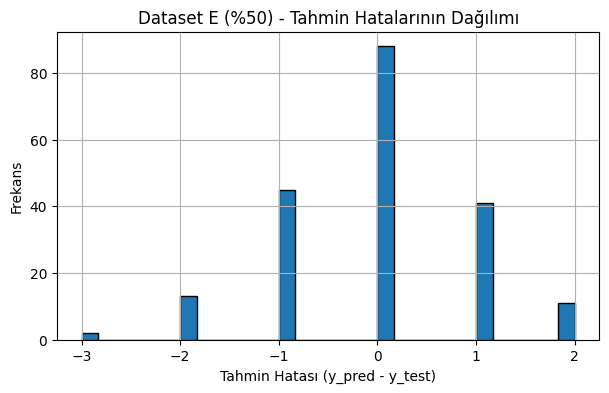

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset E (%50)")

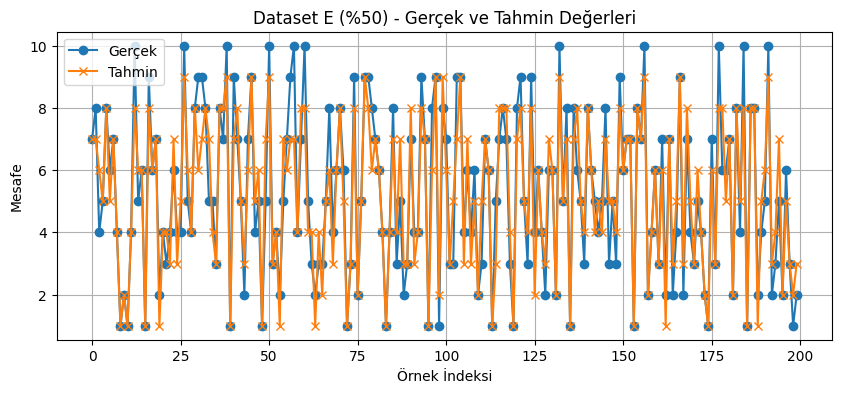

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset E (%50)")

### Eğitim Kümesinin %25'i

In [ ]:
best_params = get_best_params(X_train_quarter, X_test, y_train_quarter, y_test, n_trials=N_TRIALS)
model = get_best_model(X_train_quarter, y_train_quarter, best_params)
y_pred = model.predict(X_test).flatten()

y_pred = np.rint(y_pred).astype(int)
y_pred = np.clip(y_pred, 1, 10) # 0 ve 11'e yuvarlamayı düzeltmek için
y_test = y_test.astype(int)

print("\n\n\nEN İYİ HİPERPARAMETRELER:\n", best_params, end="\n\n")

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

results.append({
    "dataset": "E",
    "train_size": 0.25,
    "mse": mse,
    "mae": mae,
    "r2": r2,
    "accuracy": acc,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "best_params": best_params
})

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R2: {r2:.4f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

[I 2025-05-22 16:46:33,911] A new study created in memory with name: no-name-c0a7817f-db6d-42d5-9f5c-76ee6c8c6ad8


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:46:40,031] Trial 0 finished with value: 1.3157659769058228 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 152, 'dropout': 0.23150182164094757, 'lr': 0.00014328065717593332, 'batch_size': 64}. Best is trial 0 with value: 1.3157659769058228.


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


[I 2025-05-22 16:46:48,903] Trial 1 finished with value: 0.9693734645843506 and parameters: {'filters1': 32, 'kernel1': 5, 'filters2': 64, 'kernel2': 5, 'dense_units': 147, 'dropout': 0.3264901482484368, 'lr': 0.0008333213631086446, 'batch_size': 64}. Best is trial 1 with value: 0.9693734645843506.


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


[I 2025-05-22 16:50:14,554] Trial 28 finished with value: 0.9222971200942993 and parameters: {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 162, 'dropout': 0.41154737897736565, 'lr': 0.00047329268257855135, 'batch_size': 16}. Best is trial 5 with value: 0.8061743974685669.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


[I 2025-05-22 16:50:22,991] Trial 29 finished with value: 1.0105968713760376 and parameters: {'filters1': 16, 'kernel1': 3, 'filters2': 64, 'kernel2': 3, 'dense_units': 159, 'dropout': 0.43778355977120964, 'lr': 0.0001859449360975235, 'batch_size': 16}. Best is trial 5 with value: 0.8061743974685669.


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step



EN İYİ HİPERPARAMETRELER:
 {'filters1': 16, 'kernel1': 5, 'filters2': 64, 'kernel2': 3, 'dense_units': 165, 'dropout': 0.2022833368422153, 'lr': 0.0033716558338086223, 'batch_size': 64}

MSE: 1.4650
MAE: 0.9550
R2: 0.7881

              precision    recall  f1-score   support

           1       0.83      0.62      0.71        16
           2       0.47      0.35      0.40        20
           3       0.29      0.23      0.26        22
           4       0.24      0.15      0.18        27
           5       0.18      0.26      0.21        23
           6       0.27      0.35      0.30        20
           7       0.14      0.22      0.17        23
           8       0.28      0.38      0.32        21
           9       0.27      0.24      0.25        17
          10       0.00      0.00      0.00        11

    accuracy                           0.28       200
   macro avg       0.30      0.28      0.28       200
weighted avg       0.29      0.2

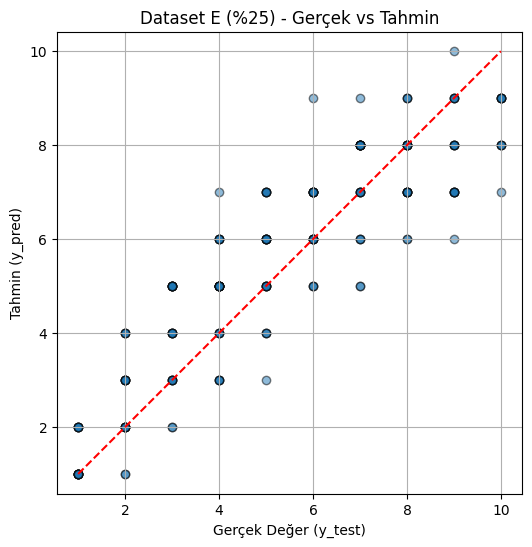

In [ ]:
plot_test_vs_pred(y_test, y_pred, "Dataset E (%25)")

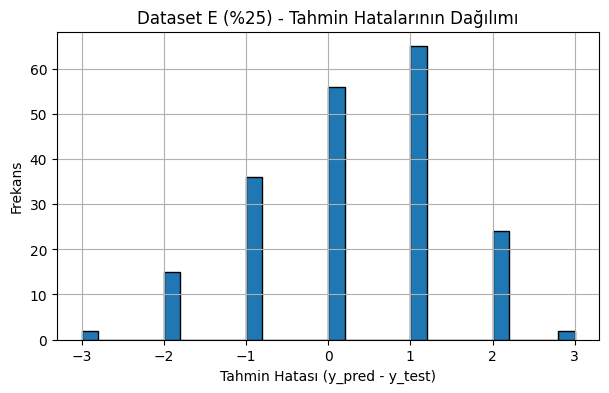

In [ ]:
plot_pred_distribution(y_test, y_pred, "Dataset E (%25)")

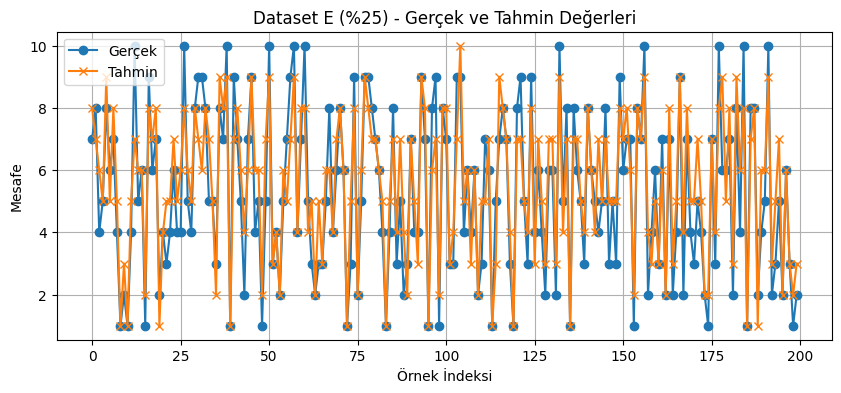

In [ ]:
plot_pred_series(y_test, y_pred, "Dataset E (%25)")

## SONUÇLAR

In [ ]:
# Sonuçları Dataframe'e çevir.
results_df = pd.DataFrame(results)

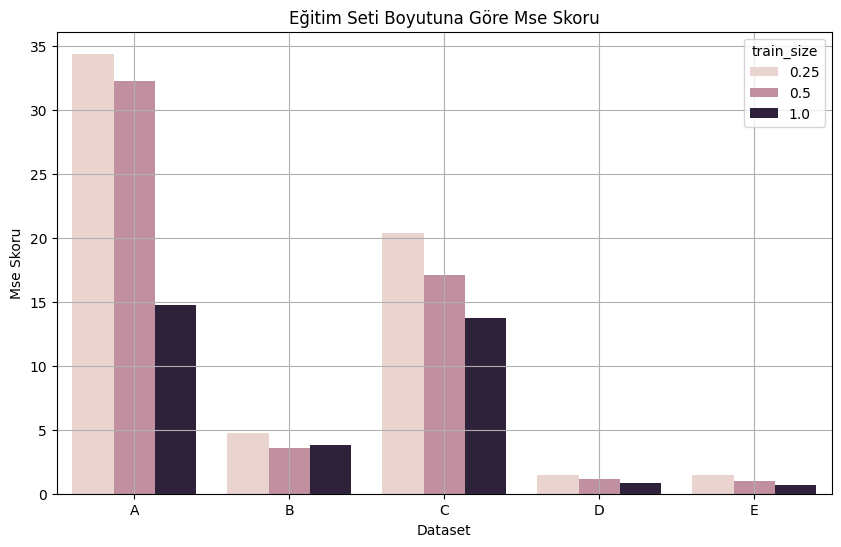

In [ ]:
plot_results(results_df, "mse")

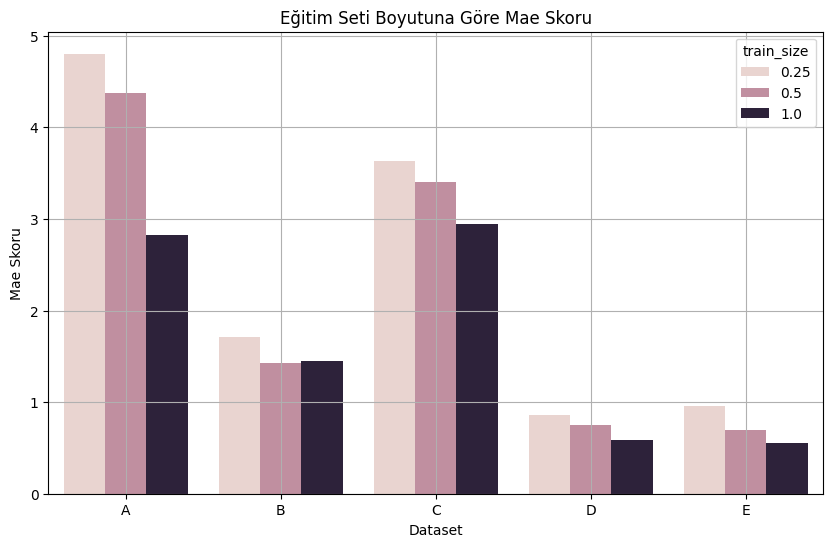

In [ ]:
plot_results(results_df, "mae")

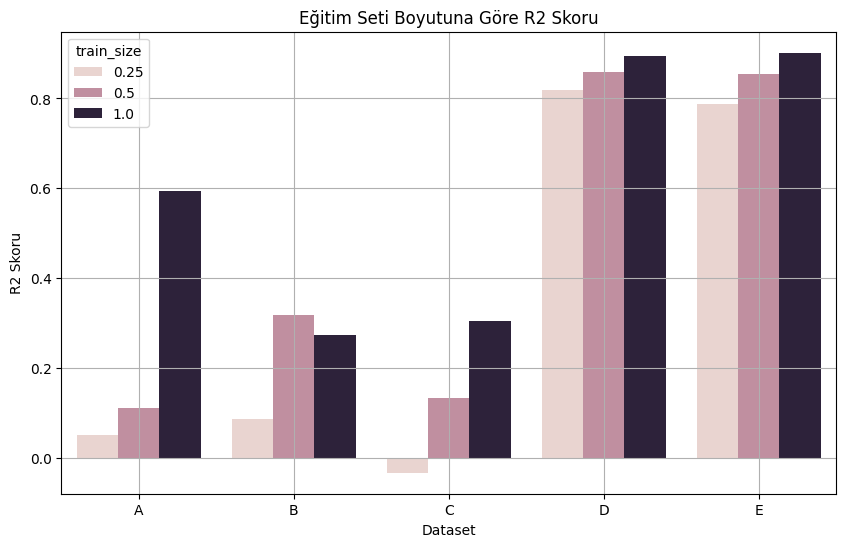

In [ ]:
plot_results(results_df, "r2")

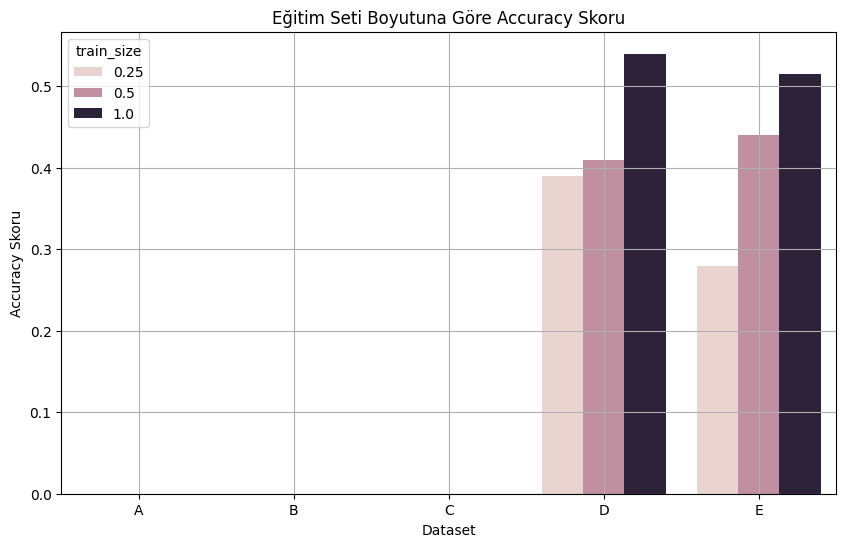

In [ ]:
plot_results(results_df, "accuracy")

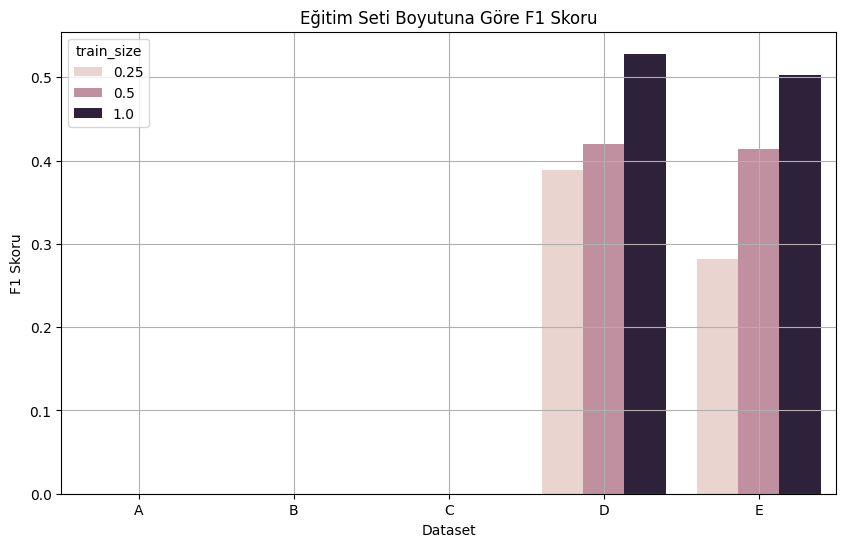

In [ ]:
plot_results(results_df, "f1")

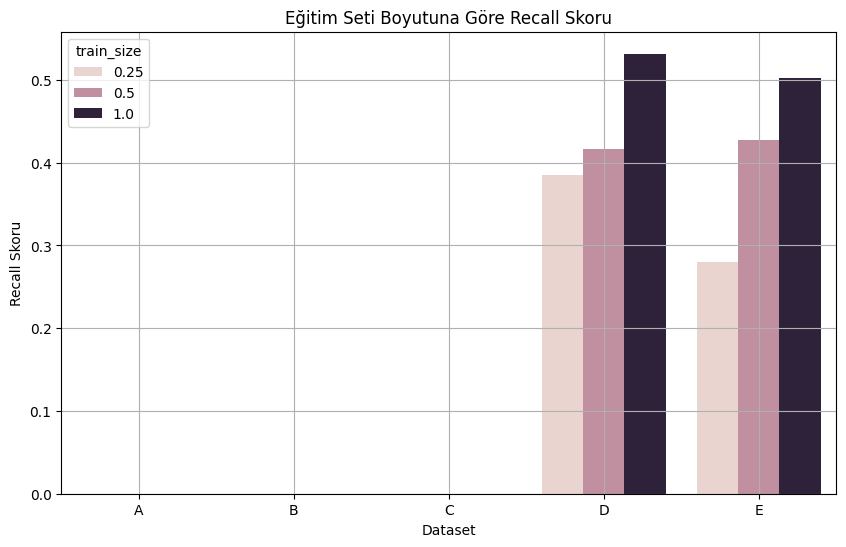

In [ ]:
plot_results(results_df, "recall")

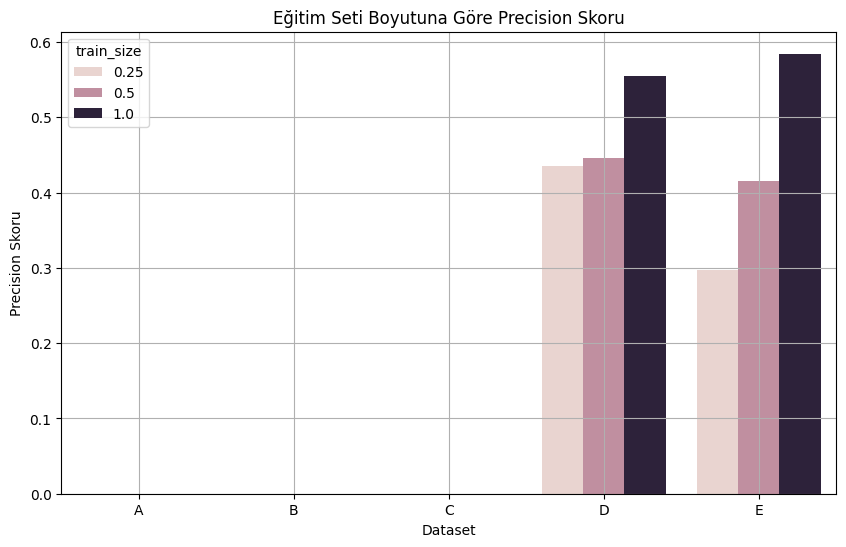

In [ ]:
plot_results(results_df, "precision")